In [ ]:
!unzip /content/drive/MyDrive/ai_in_manufacturing/2016_phm_data_challenge.zip

Archive:  /content/drive/MyDrive/ai_in_manufacturing/2016_phm_data_challenge.zip
   creating: 2016 PHM DATA CHALLENGE CMP DATA SET/
   creating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/
   creating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test/
  inflating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test/CMP-test-000.csv  
  inflating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test/CMP-test-001.csv  
  inflating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test/CMP-test-002.csv  
  inflating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test/CMP-test-003.csv  
  inflating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test/CMP-test-004.csv  
  inflating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test/CMP-test-005.csv  
  inflating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test/CMP-test-006.csv  
  inflating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test/CMP-test-007.csv  
  inflating: 2016 PHM DATA CHALLENGE CMP DATA SET/CMP-data/test/CMP-test-008.cs

In [ ]:
import pandas as pd, glob; R='/content/2016 PHM DATA CHALLENGE CMP DATA SET/'; fs=sorted(glob.glob(R+'CMP-data/training/*.csv')); d=pd.read_csv(fs[0]); print(len(fs), d.shape); print(d.dtypes.to_string()); print(d.head(3).T.to_string()); tr=pd.concat([pd.read_csv(f) for f in fs]); print(tr.shape, tr.groupby(['WAFER_ID','STAGE']).ngroups); print(tr.describe().T.to_string()); y=pd.read_csv(R+'CMP-training-removalrate.csv'); print(y.head(), y.shape); print(y.describe()); yt=pd.read_csv(R+'CMP-test-removalrate.csv'); print(yt.shape); print(tr.groupby(['STAGE','CHAMBER']).WAFER_ID.nunique())

185 (3663, 25)
MACHINE_ID                        int64
MACHINE_DATA                      int64
TIMESTAMP                       float64
WAFER_ID                          int64
STAGE                            object
CHAMBER                         float64
USAGE_OF_BACKING_FILM           float64
USAGE_OF_DRESSER                float64
USAGE_OF_POLISHING_TABLE        float64
USAGE_OF_DRESSER_TABLE          float64
PRESSURIZED_CHAMBER_PRESSURE    float64
MAIN_OUTER_AIR_BAG_PRESSURE     float64
CENTER_AIR_BAG_PRESSURE         float64
RETAINER_RING_PRESSURE          float64
RIPPLE_AIR_BAG_PRESSURE         float64
USAGE_OF_MEMBRANE               float64
USAGE_OF_PRESSURIZED_SHEET      float64
SLURRY_FLOW_LINE_A              float64
SLURRY_FLOW_LINE_B              float64
SLURRY_FLOW_LINE_C              float64
WAFER_ROTATION                  float64
STAGE_ROTATION                  float64
HEAD_ROTATION                   float64
DRESSING_WATER_STATUS           float64
EDGE_AIR_BAG_PRESSURE    

/tmp/ipykernel_1660/509666354.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  import pandas as pd, glob; R='/content/2016 PHM DATA CHALLENGE CMP DATA SET/'; fs=sorted(glob.glob(R+'CMP-data/training/*.csv')); d=pd.read_csv(fs[0]); print(len(fs), d.shape); print(d.dtypes.to_string()); print(d.head(3).T.to_string()); tr=pd.concat([pd.read_csv(f) for f in fs]); print(tr.shape, tr.groupby(['WAFER_ID','STAGE']).ngroups); print(tr.describe().T.to_string()); y=pd.read_csv(R+'CMP-training-removalrate.csv'); print(y.head(), y.shape); print(y.describe()); yt=pd.read_csv(R+'CMP-test-removalrate.csv'); print(yt.shape); print(tr.groupby(['STAGE','CHAMBER']).WAFER_ID.nunique())


(672744, 25) 1981
                                 count          mean           std           min           25%           50%           75%           max
TIMESTAMP                     672744.0  4.844186e+08  1.639134e+06  4.816344e+08  4.827736e+08  4.846534e+08  4.857991e+08  4.872682e+08
CHAMBER                       672744.0  4.223673e+00  1.333534e+00  1.000000e+00  4.000000e+00  4.000000e+00  5.000000e+00  6.000000e+00
USAGE_OF_BACKING_FILM         672744.0  4.968532e+03  2.888629e+03  1.916667e+01  2.425000e+03  5.036667e+03  7.322500e+03  1.053250e+04
USAGE_OF_DRESSER              672744.0  3.964450e+02  2.195245e+02  5.185185e+00  2.051852e+02  3.959259e+02  5.903704e+02  7.718519e+02
USAGE_OF_POLISHING_TABLE      672744.0  1.719838e+02  9.462356e+01  0.000000e+00  8.888889e+01  1.725926e+02  2.540741e+02  3.570370e+02
USAGE_OF_DRESSER_TABLE        672744.0  3.496349e+03  4.797428e+02  2.664750e+03  3.041000e+03  3.544750e+03  3.912000e+03  4.305500e+03
PRESSURIZED_CHAMBER_PRE

In [ ]:
import numpy as np
tr['T']=tr.TIMESTAMP
w = tr.groupby(['WAFER_ID','STAGE']).agg(mach=('MACHINE_ID','first'), md=('MACHINE_DATA','first'), t0=('T','min'), t1=('T','max'), n=('T','size'),
      ch=('CHAMBER', lambda s: ''.join(str(int(c)) for c in sorted(s.unique()))),
      dres=('USAGE_OF_DRESSER','first'), tab=('USAGE_OF_POLISHING_TABLE','first'), bf=('USAGE_OF_BACKING_FILM','first'), dt=('USAGE_OF_DRESSER_TABLE','first'),
      mem=('USAGE_OF_MEMBRANE','first'), ps=('USAGE_OF_PRESSURIZED_SHEET','first'), dws=('DRESSING_WATER_STATUS','mean'), nuniq_dres=('USAGE_OF_DRESSER','nunique')).reset_index()
w = w.merge(y, on=['WAFER_ID','STAGE'])
print(w.mach.value_counts(), w.md.value_counts().head())
print(w.groupby(['STAGE','ch']).AVG_REMOVAL_RATE.describe())
w=w[w.AVG_REMOVAL_RATE<1000]
print(w[['dres','tab','bf','dt','mem','ps','dws','n','AVG_REMOVAL_RATE']].corr().AVG_REMOVAL_RATE)
print('max nunique dres in wafer', w.nuniq_dres.max())
w=w.sort_values('t0')
for g,gg in w.groupby(['STAGE','ch']):
    print(g, np.corrcoef(gg.dres, gg.AVG_REMOVAL_RATE)[0,1], np.corrcoef(gg.tab, gg.AVG_REMOVAL_RATE)[0,1], np.corrcoef(gg.bf, gg.AVG_REMOVAL_RATE)[0,1], np.corrcoef(gg.mem, gg.AVG_REMOVAL_RATE)[0,1])
# resets
w['dres_diff']=w.groupby(['STAGE','ch']).dres.diff(); w['tab_diff']=w.groupby(['STAGE','ch']).tab.diff()
print('dres resets', (w.dres_diff< -50).sum(), 'tab resets', (w.tab_diff< -50).sum())
print(w[['t0','STAGE','ch','dres','tab','bf','AVG_REMOVAL_RATE']].head(30).to_string())
fs2=sorted(glob.glob(R+'CMP-data/test/*.csv')); te=pd.concat([pd.read_csv(f) for f in fs2]); print(te.shape, te.groupby(['WAFER_ID','STAGE']).ngroups, te.TIMESTAMP.min(), te.TIMESTAMP.max(), tr.TIMESTAMP.min(), tr.TIMESTAMP.max())
print(yt.head())


mach
2    1981
Name: count, dtype: int64 md
4    1613
1     368
Name: count, dtype: int64
           count        mean         std        min        25%        50%  \
STAGE ch                                                                    
A     123  368.0  195.359668  421.511347  138.55335  148.61745  151.15320   
      4      1.0   78.280500         NaN   78.28050   78.28050   78.28050   
      456  797.0   73.076855    6.655617   53.42655   69.69645   74.03940   
B     4      1.0   73.148400         NaN   73.14840   73.14840   73.14840   
      456  813.0   79.971632    9.155836   54.30720   73.37640   81.51060   
      46     1.0   86.311950         NaN   86.31195   86.31195   86.31195   

                  75%         max  
STAGE ch                           
A     123  153.768712  4326.15405  
      4     78.280500    78.28050  
      456   77.681400    88.70205  
B     4     73.148400    73.14840  
      456   86.756850   101.46480  
      46    86.311950    86.31195  
dres 

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2991: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


(156262, 25) 424 481638013.333 487216402.333 481634409.667 487268210.333
     WAFER_ID STAGE AVG_REMOVAL_RATE
0 -4224160678     B                ?
1 -4224160592     A                ?
2  -887170152     B                ?
3   373446766     A                ?
4 -4224160686     A                ?


/tmp/ipykernel_1660/3915815546.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  fs2=sorted(glob.glob(R+'CMP-data/test/*.csv')); te=pd.concat([pd.read_csv(f) for f in fs2]); print(te.shape, te.groupby(['WAFER_ID','STAGE']).ngroups, te.TIMESTAMP.min(), te.TIMESTAMP.max(), tr.TIMESTAMP.min(), tr.TIMESTAMP.max())


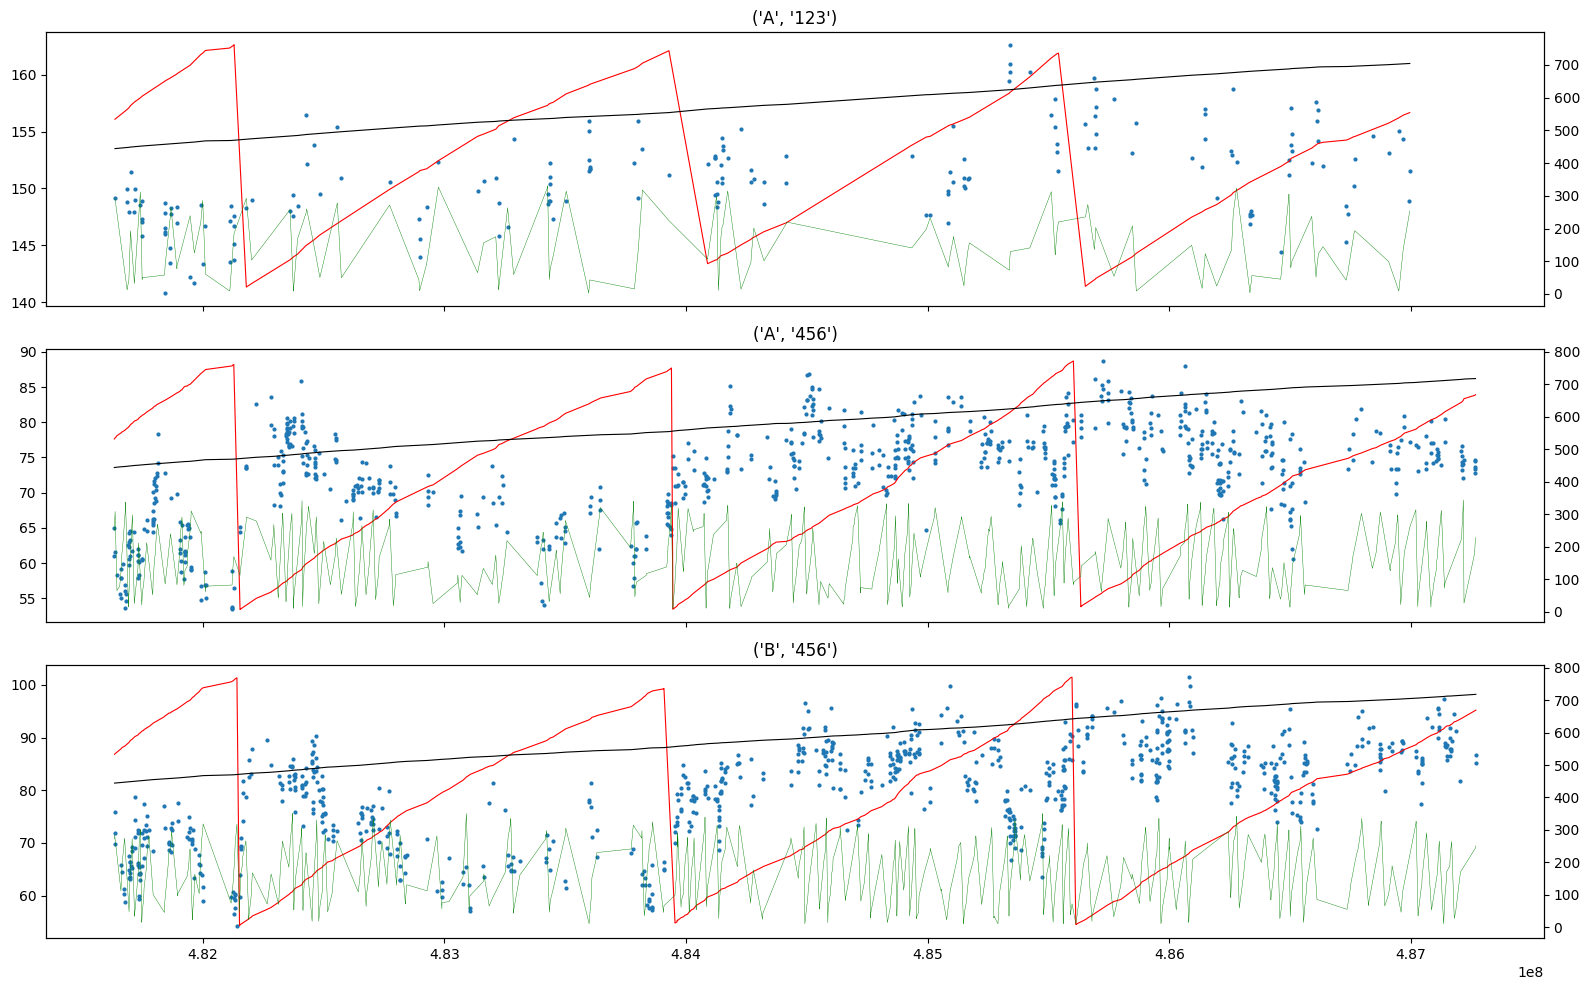

In [ ]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(3,1,figsize=(16,10),sharex=True)
for i,(g,gg) in enumerate(wf[wf.AVG_REMOVAL_RATE<1000].groupby(['STAGE','ch'])):
    if len(gg)<50: continue
    gg=gg.sort_values('t0'); k=[('A','123'),('A','456'),('B','456')].index(g)
    ax[k].scatter(gg.t0, gg.AVG_REMOVAL_RATE, s=4); ax[k].set_title(str(g))
    a2=ax[k].twinx(); a2.plot(gg.t0, gg.dres, 'r-', lw=.8); a2.plot(gg.t0, gg.tab, 'g-', lw=.3); a2.plot(gg.t0, gg.dt/6, 'k-', lw=.8)
plt.tight_layout(); plt.show()


In [ ]:
CLOCKS = ['day', 'u_dtable']
r = {}
ms = [train_twin(ftr, prep, seed=s, kind='hybrid') for s in range(2)]
r['hybrid masked random'] = metrics(fte.MRR.values, predict(ms, prep, fte)['mu'])['RMSE']
r['hybrid masked chrono'] = metrics(Bt.MRR.values, predict([train_twin(A, pA, seed=s, kind='hybrid') for s in range(2)], pA, Bt)['mu'])['RMSE']
print(r)

# Physics-Informed Digital Twin for CMP Material Removal Rate (MRR) Prediction
**ME6324: AI in Manufacturing, Group 37**

**The problem.** MRR in CMP is never measured in-line. It drifts down as the pad glazes and the dressing disk dulls, then resets when consumables are changed.
Metrology is slow and expensive, so most wafers go unchecked.

**The approach** (as proposed at the midterm):

    Process parameters & usage counters ─┬─► Latent pad-state ODE ─► Preston backbone (dynamic k_p) ─┐
                                         └─► Bounded residual net ───────────────────────────────────┴─► MRR ± σ

* **Preston backbone (modified):** `MRR_phys = k_p(z) · (P/P̄)^α · (V/V̄)^β`, with α, β ∈ (0, 2) so MRR can only go *up* with pressure and velocity.
* **Latent pad-state ODE:** `dz/dc = −λ (z − z∞)`, reset to `z = 1` by consumable intervention, solved in closed form on two time-scales:
  dresser-disk sharpness (slow, resets on dresser change) × pad glazing (fast, resets on pad conditioning) × consumable break-in drift.
* **Bounded residual net:** `r = B·tanh(NN(x))` with `B = 15 %` of the mode's mean MRR, so the AI term never dominates physics.
* **Digital-twin loop:** the twin reports uncertainty (deep ensemble + heteroscedastic head), assimilates past metrology through a Kalman/Bayesian bias update,
  and decides which wafers really need physical metrology.

**Data:** 2016 PHM Society Data Challenge (CMP), with 1,981 labelled wafers and 24 sensor channels. The 424 challenge-test wafers have no released labels, so 20 % of the labelled wafers (picked at random, interleaved in time like the challenge test) are held out as the test set, and the twin still produces predictions for the 424 challenge wafers.

## 1. Setup

In [ ]:
import os, glob, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')
torch.set_num_threads(max(1, os.cpu_count() or 1))

ROOT = '/content/2016 PHM DATA CHALLENGE CMP DATA SET/'   # unzipped dataset
ZIP = '/content/drive/MyDrive/ai_in_manufacturing/2016_phm_data_challenge.zip'
OUT = '/content/results'                                   # figures + tables for the final deck
os.makedirs(OUT, exist_ok=True)
if not os.path.isdir(ROOT):                                # fresh runtime: mount Drive and unzip the dataset
    from google.colab import drive
    drive.mount('/content/drive')
    import zipfile; zipfile.ZipFile(ZIP).extractall('/content')

CFG = dict(
    seed=0,
    outlier_mrr=1000.0,      # MRR > 1000 nm/min are physical anomalies (4 wafers), removed
    test_frac=0.2,           # labelled wafers held out as the test set (challenge test labels are not released)
    resid_bound=0.15,        # residual net bounded to ±15 % of the mode's mean MRR
    resid_reg=1.0,           # penalty on (residual / bound)^2, keeps physics doing most of the work
    n_ensemble=5,            # deep-ensemble members for the final twin
    n_folds=5,               # CV folds for out-of-fold residuals (used by the assimilation step)
    cv_seeds=2,              # ensemble members per CV fold
    epochs_phys=1500, epochs_joint=2500,
    metrology_lag_h=0.0,     # hours before a measured wafer's result is available to the twin
)
MODES = ['A123', 'A456', 'B456']   # 3 operating modes: stage A on chambers 1-3, stage A/B on chambers 4-6

def set_seed(s):
    np.random.seed(s); torch.manual_seed(s)
set_seed(CFG['seed'])
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
print('torch', torch.__version__)

torch 2.11.0+cpu


## 2. Load raw sensor data and labels

In [ ]:
def load_raw(split):
    files = sorted(glob.glob(os.path.join(ROOT, 'CMP-data', split, '*.csv')))
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

raw_tr, raw_te = load_raw('training'), load_raw('test')
lab_tr = pd.read_csv(ROOT + 'CMP-training-removalrate.csv')
lab_te = pd.read_csv(ROOT + 'CMP-test-removalrate.csv')
lab_te['AVG_REMOVAL_RATE'] = pd.to_numeric(lab_te.AVG_REMOVAL_RATE, errors='coerce')   # blank in this release
print('raw rows  train/test:', raw_tr.shape, raw_te.shape)
print('wafers    train/test:', len(lab_tr), len(lab_te), '| challenge-test labels available:', lab_te.AVG_REMOVAL_RATE.notna().sum())

raw rows  train/test: (672744, 25) (156262, 25)
wafers    train/test: 1981 424 | challenge-test labels available: 0


## 3. Wafer-level feature engineering (physics quantities + consumable clocks)

In [ ]:
SHORT = {
    'USAGE_OF_BACKING_FILM': 'u_film', 'USAGE_OF_DRESSER': 'u_dresser', 'USAGE_OF_POLISHING_TABLE': 'u_table',
    'USAGE_OF_DRESSER_TABLE': 'u_dtable', 'USAGE_OF_MEMBRANE': 'u_membrane', 'USAGE_OF_PRESSURIZED_SHEET': 'u_sheet',
    'PRESSURIZED_CHAMBER_PRESSURE': 'p_chamber', 'MAIN_OUTER_AIR_BAG_PRESSURE': 'p_main_outer',
    'CENTER_AIR_BAG_PRESSURE': 'p_center', 'RETAINER_RING_PRESSURE': 'p_retainer',
    'RIPPLE_AIR_BAG_PRESSURE': 'p_ripple', 'EDGE_AIR_BAG_PRESSURE': 'p_edge',
    'SLURRY_FLOW_LINE_A': 'slurry_a', 'SLURRY_FLOW_LINE_B': 'slurry_b', 'SLURRY_FLOW_LINE_C': 'slurry_c',
    'WAFER_ROTATION': 'rot_wafer', 'STAGE_ROTATION': 'rot_stage', 'HEAD_ROTATION': 'rot_head',
}
KEY = ['WAFER_ID', 'STAGE']

def wafer_features(raw):
    df = raw.rename(columns=SHORT).sort_values(KEY + ['TIMESTAMP']).reset_index(drop=True)
    df['dt'] = df.groupby(KEY).TIMESTAMP.diff().fillna(0).clip(0, 10)
    # Preston quantities: P = head chamber pressure loading the wafer, V = platen (stage) rotation speed
    df['P'], df['V'] = df.p_chamber, df.rot_stage
    df['PV'] = df.P * df.V
    df['work'] = df.PV * df.dt                     # mechanical work proxy, integral of P·V dt
    g = df.groupby(KEY)
    base = g.agg(machine_data=('MACHINE_DATA', 'first'), t_start=('TIMESTAMP', 'min'), t_end=('TIMESTAMP', 'max'),
                 n_rows=('TIMESTAMP', 'size'), work=('work', 'sum'), dressing_water=('DRESSING_WATER_STATUS', 'mean'),
                 u_film=('u_film', 'first'), u_dresser=('u_dresser', 'first'), u_table=('u_table', 'first'),
                 u_dtable=('u_dtable', 'first'), u_membrane=('u_membrane', 'first'), u_sheet=('u_sheet', 'first'))
    act = df[df.V > 0]                              # rows where the platen is turning (actual polishing)
    ga = act.groupby(KEY)
    cols = ['P', 'V', 'PV', 'rot_head', 'rot_wafer', 'p_main_outer', 'p_center', 'p_edge', 'p_retainer', 'p_ripple',
            'slurry_a', 'slurry_b', 'slurry_c']
    am = ga[cols].mean()
    am['P_std'], am['V_std'], am['active_time'] = ga.P.std(), ga.V.std(), ga.dt.sum()
    f = base.join(am, how='left').reset_index()
    f['duration'] = f.t_end - f.t_start
    f['mode'] = f.STAGE + np.where(f.machine_data == 1, '123', '456')
    return f

lab_all = wafer_features(raw_tr).merge(lab_tr, on=KEY, how='left').rename(columns={'AVG_REMOVAL_RATE': 'MRR'})
fsub = wafer_features(raw_te).merge(lab_te, on=KEY, how='left').rename(columns={'AVG_REMOVAL_RATE': 'MRR'})  # challenge test (unlabelled)

# Outlier removal (physical anomalies > 1000 nm/min; normal range is 53-170 nm/min)
n_out = (lab_all.MRR > CFG['outlier_mrr']).sum()
lab_all = lab_all[lab_all.MRR <= CFG['outlier_mrr']].reset_index(drop=True)

# The challenge test labels are blank in this release, so 20 % of the labelled wafers are held out as our test set.
# The split is random, so held-out wafers are interleaved in time with training wafers, just like the challenge test set.
is_test = np.random.default_rng(CFG['seed']).random(len(lab_all)) < CFG['test_frac']
ftr, fte = lab_all[~is_test].reset_index(drop=True), lab_all[is_test].reset_index(drop=True)
print(f'removed {n_out} outliers -> train {len(ftr)}, held-out test {len(fte)}, unlabelled challenge test {len(fsub)} wafers')

T0 = min(ftr.t_start.min(), fte.t_start.min(), fsub.t_start.min())
for f in (ftr, fte, fsub):
    f['day'] = (f.t_start - T0) / 86400.0
    f['mode_id'] = f['mode'].map({m: i for i, m in enumerate(MODES)}).astype(int)

FEATS = ['P', 'V', 'PV', 'P_std', 'V_std', 'rot_head', 'rot_wafer', 'p_main_outer', 'p_center', 'p_edge', 'p_retainer',
         'p_ripple', 'slurry_a', 'slurry_b', 'slurry_c', 'active_time', 'duration', 'n_rows', 'work', 'dressing_water',
         'u_film', 'u_dresser', 'u_table', 'u_dtable', 'u_membrane', 'u_sheet', 'day']
CLOCKS = ['day', 'u_dtable']   # monotone clocks: never reset, so they leave the training range in the future
med = ftr.groupby('mode')[FEATS].median()
for f in (ftr, fte, fsub):                          # fill wafers with no active rows using the training medians of their mode
    for m in MODES:
        idx = f['mode'] == m
        f.loc[idx, FEATS] = f.loc[idx, FEATS].fillna(med.loc[m])
print(ftr.groupby('mode').MRR.describe().round(2))

removed 4 outliers -> train 1564, held-out test 413, unlabelled challenge test 424 wafers
      count    mean   std     min     25%     50%     75%     max
mode                                                             
A123  288.0  151.41  3.96  138.55  148.89  151.15  153.86  162.64
A456  632.0   73.13  6.66   53.43   69.88   74.18   77.85   88.06
B456  644.0   79.93  9.09   57.37   73.27   81.25   86.77  101.46


## 4. Look at the data: the MRR sawtooth (dresser wear and reset) the twin must capture

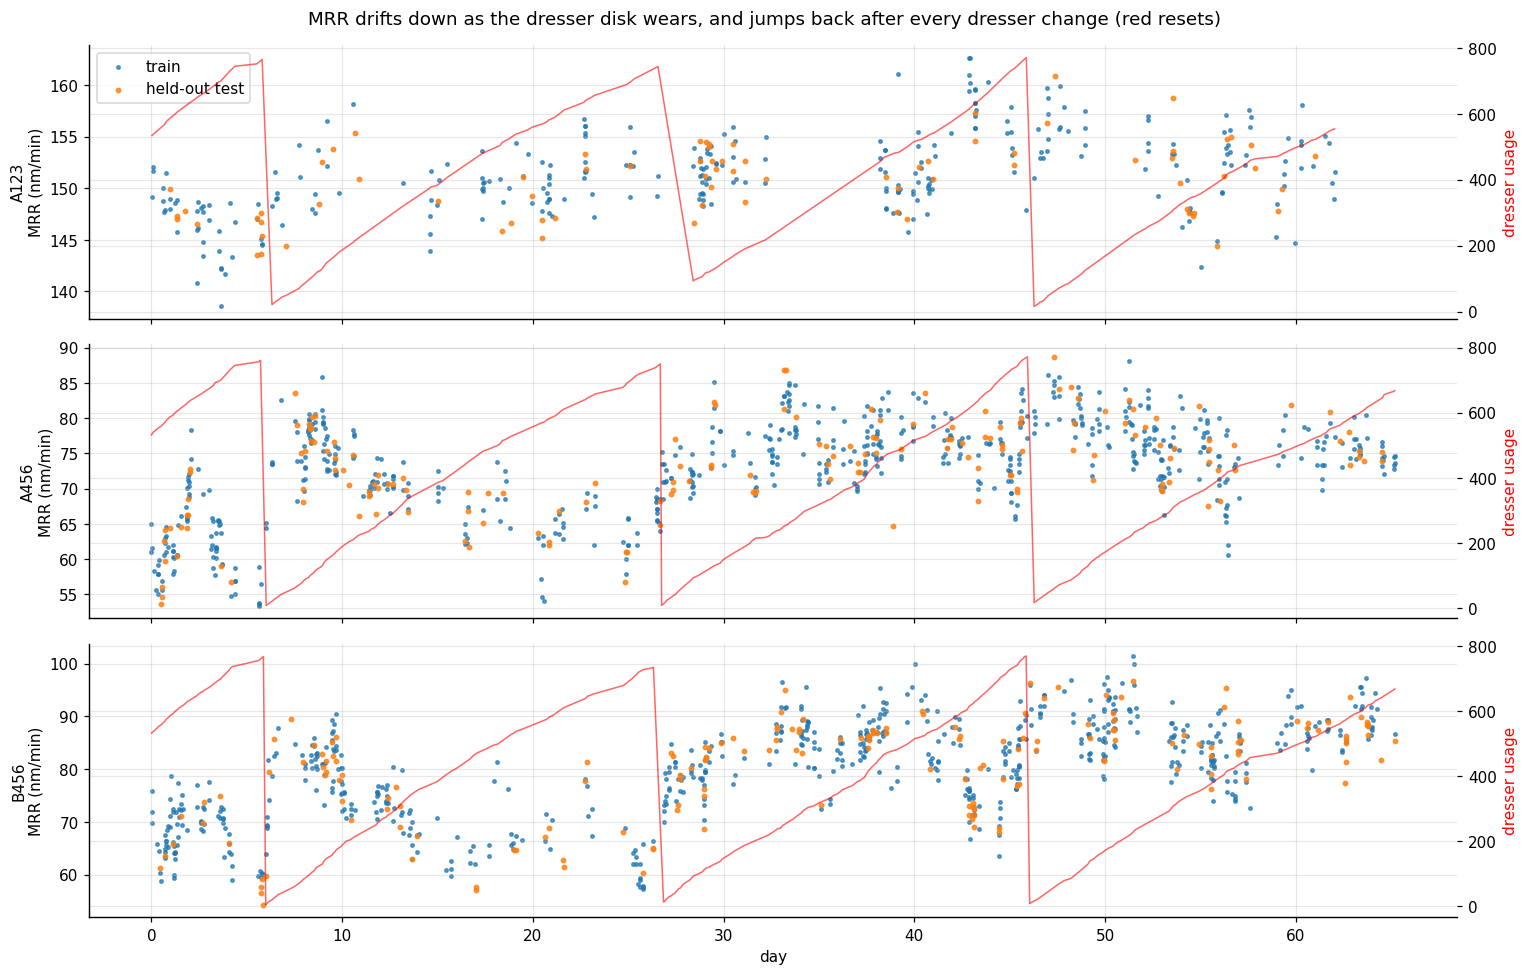

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, m in zip(axes, MODES):
    a, b = ftr[ftr['mode'] == m], fte[fte['mode'] == m]
    ax.scatter(a.day, a.MRR, s=5, label='train', alpha=.7)
    ax.scatter(b.day, b.MRR, s=8, c='tab:orange', label='held-out test', alpha=.8)
    ax.set_ylabel(f'{m}\nMRR (nm/min)')
    ax2 = ax.twinx()
    s = pd.concat([a, b]).sort_values('day')
    ax2.plot(s.day, s.u_dresser, 'r-', lw=1, alpha=.6, label='dresser usage')
    ax2.set_ylabel('dresser usage', color='r')
axes[0].legend(loc='upper left'); axes[-1].set_xlabel('day')
fig.suptitle('MRR drifts down as the dresser disk wears, and jumps back after every dresser change (red resets)')
plt.tight_layout(); plt.savefig(f'{OUT}/fig1_sawtooth.png', bbox_inches='tight'); plt.show()

## 5. Tensors and the physics-informed hybrid model

In [ ]:
class Prep:
    """Standardises features and builds the physics inputs for the twin."""
    def fit(self, df):
        self.sc = StandardScaler().fit(df[FEATS])
        self.P_bar = df.groupby('mode_id').P.mean().reindex(range(len(MODES))).values
        self.V_bar = df.groupby('mode_id').V.mean().reindex(range(len(MODES))).values
        self.mrr_mean = df.groupby('mode_id').MRR.mean().reindex(range(len(MODES))).values
        self.g_lo, self.g_hi = df.u_dtable.min(), df.u_dtable.max()
        return self
    def __call__(self, df):
        m = df.mode_id.values
        x = np.hstack([self.sc.transform(df[FEATS]), np.eye(len(MODES))[m]])
        P = np.maximum(df.P.values, 0.05 * self.P_bar[m]); V = np.maximum(df.V.values, 0.05 * self.V_bar[m])
        t = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
        return dict(x=t(x), m=torch.tensor(m, dtype=torch.long),
                    d=t(df.u_dresser.values / 800.0),           # dresser-disk life clock  (resets on dresser change)
                    u=t(df.u_table.values / 400.0),             # pad/table clock          (resets on pad conditioning)
                    g=t((df.u_dtable.values - self.g_lo) / (self.g_hi - self.g_lo)),   # long-term consumable clock (0-1 on train)
                    lp=t(np.log(P / self.P_bar[m])), lv=t(np.log(V / self.V_bar[m])))

class HybridTwin(nn.Module):
    """MRR = k_p(z)·(P/P̄)^α·(V/V̄)^β  +  B·tanh(NN(x)).
    k_p(z) = k_mode · z_dresser(d) · z_pad(u) · z_breakin(g). z_dresser and z_pad are closed-form solutions of
    dz/dc = −λ (z − (1 − A)), z(0) = 1 (reset at consumable intervention); z_breakin solves dz/dg = λ (1 − z)."""
    def __init__(self, n_in, mrr_mean, hidden=64, bound=0.15, use_ode=True, use_pv=True, use_resid=True, mask_clocks=True):
        super().__init__()
        M = len(MODES)
        # Monotone clocks (calendar time, dresser-table usage) enter ONLY through the physics state, never the residual net,
        # so the AI term cannot extrapolate along time it has never seen.
        mask = torch.ones(n_in)
        if mask_clocks: mask[[FEATS.index(c) for c in CLOCKS]] = 0.0
        self.register_buffer('in_mask', mask)
        self.use_ode, self.use_pv, self.use_resid = use_ode, use_pv, use_resid
        self.log_k = nn.Parameter(torch.log(torch.tensor(mrr_mean, dtype=torch.float32)))
        self.raw_alpha = nn.Parameter(torch.full((M,), -2.0)); self.raw_beta = nn.Parameter(torch.full((M,), -2.0))
        self.raw_lam_d = nn.Parameter(torch.zeros(M)); self.raw_amp_d = nn.Parameter(torch.full((M,), -1.0))
        self.raw_lam_p = nn.Parameter(torch.zeros(M)); self.raw_amp_p = nn.Parameter(torch.full((M,), -3.0))
        self.raw_lam_g = nn.Parameter(torch.zeros(M)); self.raw_amp_g = nn.Parameter(torch.full((M,), -1.0))
        self.net = nn.Sequential(nn.Linear(n_in, hidden), nn.SiLU(), nn.Dropout(0.1),
                                 nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 2))
        self.register_buffer('bound', bound * torch.tensor(mrr_mean, dtype=torch.float32))

    def physics_params(self):
        return [p for n, p in self.named_parameters() if not n.startswith('net.')]

    def ode(self, m, d, u, g):
        lam_d, amp_d = 3 * F.softplus(self.raw_lam_d[m]), torch.sigmoid(self.raw_amp_d[m])
        lam_p, amp_p = 3 * F.softplus(self.raw_lam_p[m]), 0.5 * torch.sigmoid(self.raw_amp_p[m])
        z_d = (1 - amp_d) + amp_d * torch.exp(-lam_d * d)      # dresser sharpness: 1 → 1−A_d
        z_p = (1 - amp_p) + amp_p * torch.exp(-lam_p * u)      # pad glazing:       1 → 1−A_p
        lam_g, amp_g = 3 * F.softplus(self.raw_lam_g[m]), 0.5 * torch.sigmoid(self.raw_amp_g[m])
        z_g = 1 - amp_g * torch.exp(-lam_g * g)                 # consumable break-in: 1−A_g → 1, saturates (safe to extrapolate)
        return z_d, z_p, z_g

    def forward(self, b):
        m = b['m']
        log_kp = self.log_k[m]
        if self.use_ode:
            z_d, z_p, z_g = self.ode(m, b['d'], b['u'], b['g'])
            log_kp = log_kp + torch.log(z_d) + torch.log(z_p) + torch.log(z_g)
        log_phys = log_kp
        if self.use_pv:
            log_phys = log_phys + 2 * torch.sigmoid(self.raw_alpha[m]) * b['lp'] + 2 * torch.sigmoid(self.raw_beta[m]) * b['lv']
        phys = torch.exp(log_phys)
        h = self.net(b['x'] * self.in_mask)
        resid = self.bound[m] * torch.tanh(h[:, 0]) if self.use_resid else torch.zeros_like(phys)
        logvar = torch.clamp(h[:, 1], -6, 6)
        return phys + resid, logvar, phys, resid, torch.exp(log_kp)

def _sub(b, idx):
    return {k: v[idx] for k, v in b.items()}

def train_twin(df_tr, prep, seed=0, kind='hybrid', val_frac=0.15, verbose=False):
    """kind: 'preston' | 'physics' (Preston + ODE) | 'hybrid' (full twin) | 'blackbox' (same NN, no physics)."""
    set_seed(seed)
    b = prep(df_tr); y = torch.tensor(df_tr.MRR.values, dtype=torch.float32)
    n = len(y); perm = np.random.permutation(n); nv = int(val_frac * n)
    iv, it = torch.tensor(perm[:nv]), torch.tensor(perm[nv:])
    cfg = dict(preston=dict(use_ode=False, use_pv=True, use_resid=False),
               physics=dict(use_ode=True, use_pv=True, use_resid=False),
               hybrid=dict(use_ode=True, use_pv=True, use_resid=True),
               blackbox=dict(use_ode=False, use_pv=False, use_resid=True))[kind]
    bound = 1.0 if kind == 'blackbox' else CFG['resid_bound']
    model = HybridTwin(b['x'].shape[1], prep.mrr_mean, bound=bound, mask_clocks=(kind != 'blackbox'), **cfg)
    bt, bv, yt, yv = _sub(b, it), _sub(b, iv), y[it], y[iv]

    # Phase 1: fit the physics backbone alone (skipped for the black-box model)
    if kind != 'blackbox':
        net_flag = model.use_resid; model.use_resid = False
        opt = torch.optim.Adam(model.physics_params(), lr=0.03)
        for ep in range(CFG['epochs_phys']):
            opt.zero_grad(); mu = model(bt)[0]; loss = F.mse_loss(mu, yt); loss.backward(); opt.step()
        model.use_resid = net_flag

    # Phase 2: joint training with the bounded residual and heteroscedastic variance head
    opt = torch.optim.Adam([{'params': model.physics_params(), 'lr': 3e-3},
                            {'params': model.net.parameters(), 'lr': 3e-3, 'weight_decay': 1e-4}])
    best, best_state, bad = np.inf, None, 0
    for ep in range(CFG['epochs_joint']):
        model.train(); opt.zero_grad()
        mu, logvar, phys, resid, _ = model(bt)
        mse = F.mse_loss(mu, yt)
        nll = 0.5 * (logvar + (yt - mu.detach()) ** 2 / torch.exp(logvar)).mean()   # variance head, mean detached
        reg = ((resid / model.bound[bt['m']]) ** 2).mean() if model.use_resid and kind != 'blackbox' else 0.0
        loss = mse + 0.1 * nll + CFG['resid_reg'] * reg                                          # reg keeps physics doing most of the work
        loss.backward(); opt.step()
        if ep % 25 == 0:
            model.eval()
            with torch.no_grad():
                v = F.mse_loss(model(bv)[0], yv).item()
            if v < best - 1e-4: best, bad, best_state = v, 0, {k: t.clone() for k, t in model.state_dict().items()}
            else: bad += 1
            if bad > 30: break
    model.load_state_dict(best_state); model.eval()
    if verbose: print(f'  {kind} seed {seed}: val RMSE {np.sqrt(best):.3f}  (stopped ep {ep})')
    return model

@torch.no_grad()
def predict(models, prep, df):
    b = prep(df)
    outs = [m(b) for m in models]
    mu = torch.stack([o[0] for o in outs]).numpy()
    ale = torch.stack([torch.exp(o[1]) for o in outs]).numpy()
    return dict(mu=mu.mean(0), epi_var=mu.var(0), ale_var=ale.mean(0),
                phys=torch.stack([o[2] for o in outs]).numpy().mean(0),
                resid=torch.stack([o[3] for o in outs]).numpy().mean(0),
                kp=torch.stack([o[4] for o in outs]).numpy().mean(0))

def metrics(y, p):
    e = p - y
    return dict(RMSE=float(np.sqrt(np.mean(e ** 2))), MSE=float(np.mean(e ** 2)), MAE=float(np.mean(np.abs(e))),
                R2=float(1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2)), MaxAE=float(np.max(np.abs(e))))

## 6. Train the digital twin (deep ensemble) and the physics/black-box ablations on the full training set

In [ ]:
prep = Prep().fit(ftr)
t0 = time.time()
twin = [train_twin(ftr, prep, seed=s, kind='hybrid', verbose=True) for s in range(CFG['n_ensemble'])]
abl = {k: [train_twin(ftr, prep, seed=s, kind=k) for s in range(3)] for k in ['preston', 'physics', 'blackbox']}
print(f'trained in {time.time() - t0:.0f}s')

# Classical black-box baselines
Xtr = np.hstack([ftr[FEATS].values, np.eye(3)[ftr.mode_id]]); Xte = np.hstack([fte[FEATS].values, np.eye(3)[fte.mode_id]])
def make_gbm(seed=0):
    return HistGradientBoostingRegressor(max_iter=800, learning_rate=0.03, max_leaf_nodes=31, min_samples_leaf=10,
                                         l2_regularization=1.0, random_state=seed)
gbm = make_gbm().fit(Xtr, ftr.MRR)
sc_r = StandardScaler().fit(Xtr); ridge = RidgeCV(alphas=np.logspace(-3, 3, 20)).fit(sc_r.transform(Xtr), ftr.MRR)

P_te = {
    'Mode mean': fte['mode'].map(ftr.groupby('mode').MRR.mean()).values,
    'Linear (Ridge)': ridge.predict(sc_r.transform(Xte)),
    'Black-box GBM': gbm.predict(Xte),
    'Black-box NN': predict(abl['blackbox'], prep, fte)['mu'],
    'Preston (static k_p)': predict(abl['preston'], prep, fte)['mu'],
    'Preston + pad-state ODE': predict(abl['physics'], prep, fte)['mu'],
}
twin_te = predict(twin, prep, fte)
P_te['Hybrid twin (ours)'] = twin_te['mu']
res = pd.DataFrame({k: metrics(fte.MRR.values, v) for k, v in P_te.items()}).T
print(res.round(3))

  hybrid seed 0: val RMSE 4.509  (stopped ep 1950)
  hybrid seed 1: val RMSE 4.104  (stopped ep 950)
  hybrid seed 2: val RMSE 4.360  (stopped ep 925)
  hybrid seed 3: val RMSE 4.246  (stopped ep 875)
  hybrid seed 4: val RMSE 4.101  (stopped ep 1000)
trained in 418s
                          RMSE     MSE    MAE     R2   MaxAE
Mode mean                7.520  56.552  5.827  0.936  25.626
Linear (Ridge)           5.498  30.233  4.241  0.966  24.844
Black-box GBM            3.344  11.182  2.542  0.987  13.792
Black-box NN             4.878  23.791  3.328  0.973  51.137
Preston (static k_p)     7.512  56.437  5.812  0.937  25.648
Preston + pad-state ODE  5.481  30.039  4.337  0.966  17.286
Hybrid twin (ours)       4.216  17.777  3.205  0.980  17.641


## 7. Out-of-fold predictions on the training set (needed so the twin can assimilate *honest* residuals)

In [ ]:
kf = KFold(CFG['n_folds'], shuffle=True, random_state=CFG['seed'])
oof = {k: np.zeros(len(ftr)) for k in ['Hybrid twin (ours)', 'Black-box GBM', 'Black-box NN']}
t0 = time.time()
for fold, (i_tr, i_va) in enumerate(kf.split(ftr)):
    a, v = ftr.iloc[i_tr].reset_index(drop=True), ftr.iloc[i_va].reset_index(drop=True)
    pp = Prep().fit(a)
    ms = [train_twin(a, pp, seed=100 * fold + s, kind='hybrid') for s in range(CFG['cv_seeds'])]
    oof['Hybrid twin (ours)'][i_va] = predict(ms, pp, v)['mu']
    oof['Black-box NN'][i_va] = predict([train_twin(a, pp, seed=100 * fold + s, kind='blackbox') for s in range(CFG['cv_seeds'])], pp, v)['mu']
    oof['Black-box GBM'][i_va] = make_gbm(fold).fit(Xtr[i_tr], ftr.MRR.values[i_tr]).predict(Xtr[i_va])
    print(f'fold {fold}: hybrid OOF RMSE {np.sqrt(np.mean((oof["Hybrid twin (ours)"][i_va] - v.MRR) ** 2)):.3f}  ({time.time() - t0:.0f}s)')
print({k: round(metrics(ftr.MRR.values, v)['RMSE'], 3) for k, v in oof.items()})

fold 0: hybrid OOF RMSE 4.729  (62s)
fold 1: hybrid OOF RMSE 4.442  (136s)
fold 2: hybrid OOF RMSE 4.107  (199s)
fold 3: hybrid OOF RMSE 4.029  (275s)
fold 4: hybrid OOF RMSE 4.054  (344s)
{'Hybrid twin (ours)': 4.281, 'Black-box GBM': 3.503, 'Black-box NN': 4.585}


## 8. Digital-twin state update: Bayesian (Kalman) assimilation of past metrology

In [ ]:
# Local lot / slurry-batch effects show up as a slowly varying bias b in each mode. Each past measured wafer j gives
# e_j = y_j − ŷ_j = b + ε_j with ε_j ~ N(0, σ_e² / w_j), where w_j = exp(−Δt_j / τ) down-weights old measurements, and b ~ N(0, σ_b²).
# Posterior: b̂ = Σ w_j e_j / (Σ w_j + κ),  Var(b) = σ_e² / (Σ w_j + κ),  κ = σ_e² / σ_b².
# Only wafers measured *before* the current wafer starts polishing are used (strictly causal).
LAG = CFG['metrology_lag_h'] / 24.0

def assimilate(tgt, hist, tau, kappa, K=40):
    """tgt: DataFrame(mode, day); hist: DataFrame(mode, day_end, e). Returns bias estimate b and total weight Σw."""
    b, W = np.zeros(len(tgt)), np.zeros(len(tgt))
    for m in MODES:
        h = hist[hist['mode'] == m].sort_values('day_end'); ht, he = h.day_end.values, h.e.values
        it = np.where(tgt['mode'].values == m)[0]
        pos = np.searchsorted(ht, tgt.day.values[it] - LAG, side='left')
        for i, p in zip(it, pos):
            lo = max(0, p - K); dt_ = tgt.day.values[i] - ht[lo:p]
            w = np.exp(-dt_ / tau); W[i] = w.sum(); b[i] = (w * he[lo:p]).sum() / (W[i] + kappa)
    return b, W

for f in (ftr, fte, fsub):
    f['day_end'] = (f.t_end - T0) / 86400.0

def tune_assimilation(oof_pred):
    hist = pd.DataFrame({'mode': ftr['mode'], 'day_end': ftr.day_end, 'e': ftr.MRR - oof_pred})
    best = None
    for tau in [1 / 24, 3 / 24, 6 / 24, 12 / 24, 1, 2, 4]:
        for kappa in [0.25, 0.5, 1, 2, 4, 8]:
            b, _ = assimilate(ftr, hist, tau, kappa)
            r = np.sqrt(np.mean((oof_pred + b - ftr.MRR) ** 2))
            if best is None or r < best[0]: best = (r, tau, kappa)
    return best, hist

ASSIM = {}
for name in oof:
    (r, tau, kappa), hist = tune_assimilation(oof[name])
    ASSIM[name] = dict(tau=tau, kappa=kappa, hist=hist)
    base_pred = P_te[name]
    b, W = assimilate(fte, hist, tau, kappa)
    P_te[name + ' + assimilation'] = base_pred + b
    if name == 'Hybrid twin (ours)': twin_b, twin_W = b, W
    print(f'{name:22s} tau={tau * 24:5.1f} h  kappa={kappa:<5}  train-OOF RMSE after assimilation {r:.3f}')

res = pd.DataFrame({k: metrics(fte.MRR.values, v) for k, v in P_te.items()}).T
res.index.name = 'model (test set)'
print(f'\n=== HELD-OUT TEST RESULTS ({len(fte)} wafers never seen in training) ===')
print(res.sort_values('RMSE').round(3).to_string())
res.round(4).to_csv(f'{OUT}/results_test.csv')
by_mode = pd.DataFrame({k: {m: metrics(fte.MRR.values[fte['mode'].values == m], v[fte['mode'].values == m])['RMSE'] for m in MODES}
                        for k, v in P_te.items()}).T
print('\nRMSE by mode'); print(by_mode.round(3).to_string())

Hybrid twin (ours)     tau=  3.0 h  kappa=2      train-OOF RMSE after assimilation 4.098
Black-box GBM          tau=  3.0 h  kappa=8      train-OOF RMSE after assimilation 3.478
Black-box NN           tau=  3.0 h  kappa=2      train-OOF RMSE after assimilation 4.349

=== HELD-OUT TEST RESULTS (413 wafers never seen in training) ===
                                    RMSE     MSE    MAE     R2   MaxAE
model (test set)                                                      
Black-box GBM + assimilation       3.259  10.624  2.479  0.988  13.532
Black-box GBM                      3.344  11.182  2.542  0.987  13.792
Hybrid twin (ours) + assimilation  3.800  14.439  2.839  0.984  16.432
Hybrid twin (ours)                 4.216  17.777  3.205  0.980  17.641
Black-box NN + assimilation        4.596  21.126  3.012  0.976  54.030
Black-box NN                       4.878  23.791  3.328  0.973  51.137
Preston + pad-state ODE            5.481  30.039  4.337  0.966  17.286
Linear (Ridge)             